# Task 2 — Time Series Sales Forecasting
**QSkill Internship · Slab 2 (Intermediate)**

**Goal:** use historical sales to understand trend, seasonality and unusual days, build time-based / lag / rolling features, compare forecasting approaches with a **chronological** train-test split, and forecast future sales.

**Workflow**
1. Load data & organise dates
2. Time-series cleaning (duplicates, gaps, missing values)
3. Exploratory analysis — trend, seasonality, patterns, unusual observations
4. Feature engineering — calendar, lag and rolling-window features
5. Chronological train / test split
6. Baselines and machine-learning models, with time-aware tuning
7. Evaluation — MAE, RMSE, MAPE
8. Actual vs predicted visualisation
9. Forecast the next 90 days
10. Observations about future sales and seasonal behaviour

> **Dataset note:** `../data/store_sales.csv` follows the schema of the public Kaggle *Store Item Demand Forecasting* dataset (`date, store, item, sales`). Replace it with the real `train.csv` (saved under the same name) and the notebook runs unchanged. If your data is already a single sales column, skip the `groupby` in Section 2.

## 1. Setup & loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
RS = 42

In [2]:
raw = pd.read_csv("../data/store_sales.csv")
print("Rows:", raw.shape[0], "| columns:", list(raw.columns))
raw.head()

Rows: 13149 | columns: ['date', 'store', 'item', 'sales']


,date,store,item,sales
0,2019-01-01,1,1,25
1,2019-01-01,1,2,17
2,2019-01-01,1,3,34
3,2019-01-01,2,1,32
4,2019-01-01,2,2,22


## 2. Time-series data cleaning
The raw file has one row per **date × store × item**. For a total-company forecast the rows are aggregated into one daily series. We also verify there are no duplicates, impossible values or missing days.

In [3]:
raw["date"] = pd.to_datetime(raw["date"])           # organise date information
print("Date range      :", raw["date"].min().date(), "->", raw["date"].max().date())
print("Stores / items  :", raw["store"].nunique(), "/", raw["item"].nunique())
print("Duplicate rows  :", raw.duplicated(["date", "store", "item"]).sum())
print("Missing values  :", int(raw.isna().sum().sum()))
print("Negative sales  :", int((raw["sales"] < 0).sum()))
print("Zero sales rows :", int((raw["sales"] == 0).sum()))

Date range      : 2019-01-01 -> 2022-12-31
Stores / items  : 3 / 3
Duplicate rows  : 0
Missing values  : 0
Negative sales  : 0
Zero sales rows : 0


In [4]:
daily = raw.groupby("date")["sales"].sum().sort_index()

full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
print("Days in range:", len(full_range), "| days present:", len(daily), "| missing days:", len(full_range.difference(daily.index)))

daily = daily.reindex(full_range)                   # makes any missing day explicit
daily = daily.interpolate(method="time")            # fill gaps (none here, but kept for real data)
daily.index.name = "date"
daily.name = "sales"
print("Missing after cleaning:", int(daily.isna().sum()))
daily.describe().round(1)

Days in range: 1461 | days present: 1461 | missing days: 0
Missing after cleaning: 0


count    1461.0
mean      484.2
std       134.9
min        85.0
25%       389.0
50%       466.0
75%       559.0
max      1420.0
Name: sales, dtype: float64

In [5]:
cal = pd.DataFrame({"sales": daily})
cal["year"] = cal.index.year
cal["month"] = cal.index.month
cal["dayofweek"] = cal.index.dayofweek
cal["weekday"] = cal.index.day_name()
cal.head()

,sales,year,month,dayofweek,weekday
date,,,,,
2019-01-01,231,2019,1,1,Tuesday
2019-01-02,257,2019,1,2,Wednesday
2019-01-03,261,2019,1,3,Thursday
2019-01-04,304,2019,1,4,Friday
2019-01-05,389,2019,1,5,Saturday


## 3. Exploratory analysis

### 3.1 Overall pattern and trend

Total sales by year and year-on-year growth:


,total_sales,YoY_growth_%
date,,
2019,152698,NaN
2020,168061,10.1
2021,185518,10.4
2022,201180,8.4


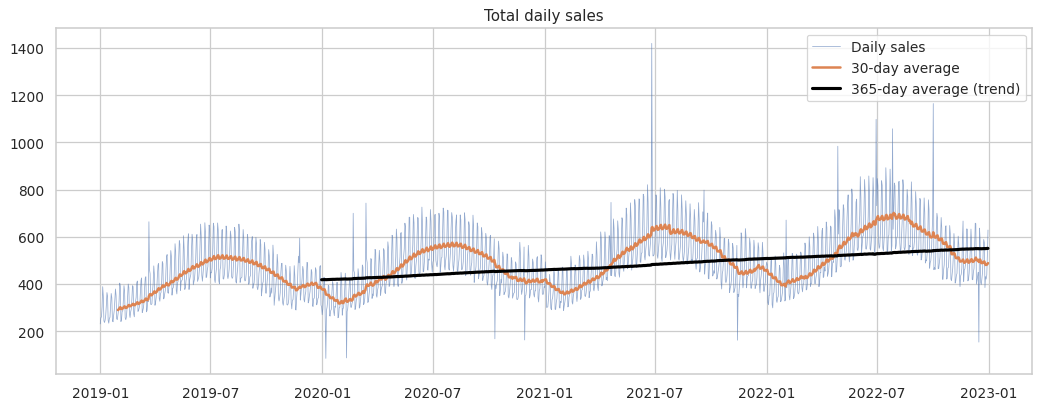

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily, lw=0.6, alpha=0.6, label="Daily sales")
ax.plot(daily.rolling(30).mean(), lw=2, label="30-day average")
ax.plot(daily.rolling(365).mean(), lw=2.5, color="black", label="365-day average (trend)")
ax.set_title("Total daily sales")
ax.legend()
plt.show()

yearly = daily.groupby(daily.index.year).sum()
print("Total sales by year and year-on-year growth:")
pd.DataFrame({"total_sales": yearly, "YoY_growth_%": (yearly.pct_change() * 100).round(1)})

### 3.2 Seasonality — weekly and yearly

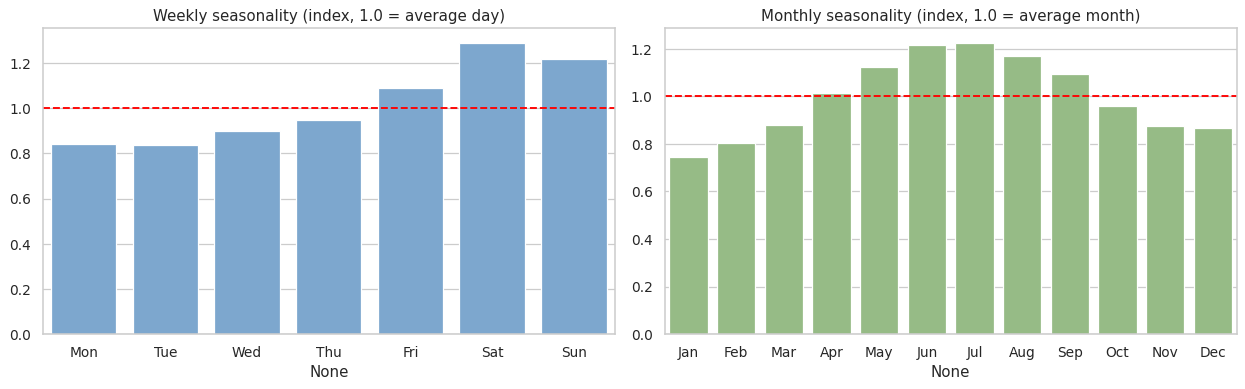

In [7]:
trend365 = daily.rolling(365, center=True, min_periods=300).mean()
ratio = (daily / trend365).dropna()          # sales relative to the yearly trend level

dow_idx = ratio.groupby(ratio.index.dayofweek).mean()
dow_idx.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
month_idx = ratio.groupby(ratio.index.month).mean()
month_idx.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=dow_idx.index, y=dow_idx.values, ax=ax[0], color="#6fa8dc")
ax[0].axhline(1, color="red", ls="--")
ax[0].set_title("Weekly seasonality (index, 1.0 = average day)")
sns.barplot(x=month_idx.index, y=month_idx.values, ax=ax[1], color="#93c47d")
ax[1].axhline(1, color="red", ls="--")
ax[1].set_title("Monthly seasonality (index, 1.0 = average month)")
plt.tight_layout()
plt.show()

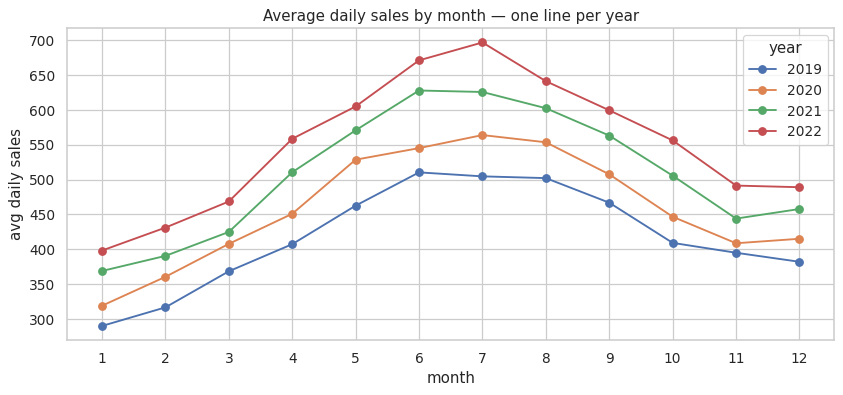

In [8]:
pivot = cal.pivot_table(index="month", columns="year", values="sales", aggfunc="mean")
pivot.plot(figsize=(11, 4.5), marker="o")
plt.title("Average daily sales by month — one line per year")
plt.xticks(range(1, 13))
plt.ylabel("avg daily sales")
plt.show()

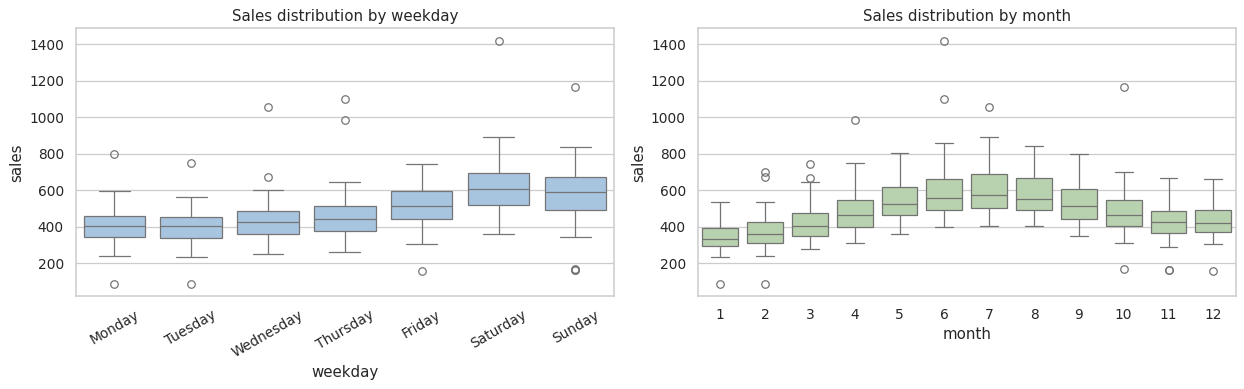

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x="weekday", y="sales", data=cal, order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ax=ax[0], color="#9fc5e8")
ax[0].tick_params(axis="x", rotation=30)
ax[0].set_title("Sales distribution by weekday")
sns.boxplot(x="month", y="sales", data=cal, ax=ax[1], color="#b6d7a8")
ax[1].set_title("Sales distribution by month")
plt.tight_layout()
plt.show()

### 3.3 Contribution of stores and items

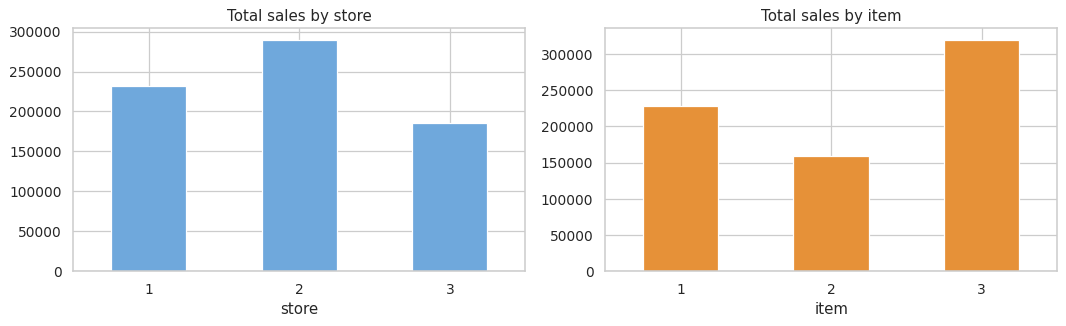

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
raw.groupby("store")["sales"].sum().plot(kind="bar", ax=ax[0], color="#6fa8dc", rot=0, title="Total sales by store")
raw.groupby("item")["sales"].sum().plot(kind="bar", ax=ax[1], color="#e69138", rot=0, title="Total sales by item")
plt.tight_layout()
plt.show()

### 3.4 Decomposition and unusual observations
A simple multiplicative decomposition separates **trend × weekly pattern × remainder**. A rolling *median* is used for the trend so that one-off spikes do not distort their neighbours. Days whose remainder is far outside the normal range (robust z-score using the median and MAD, threshold 5) are flagged as unusual — typically promotions, stock-outs or special events.

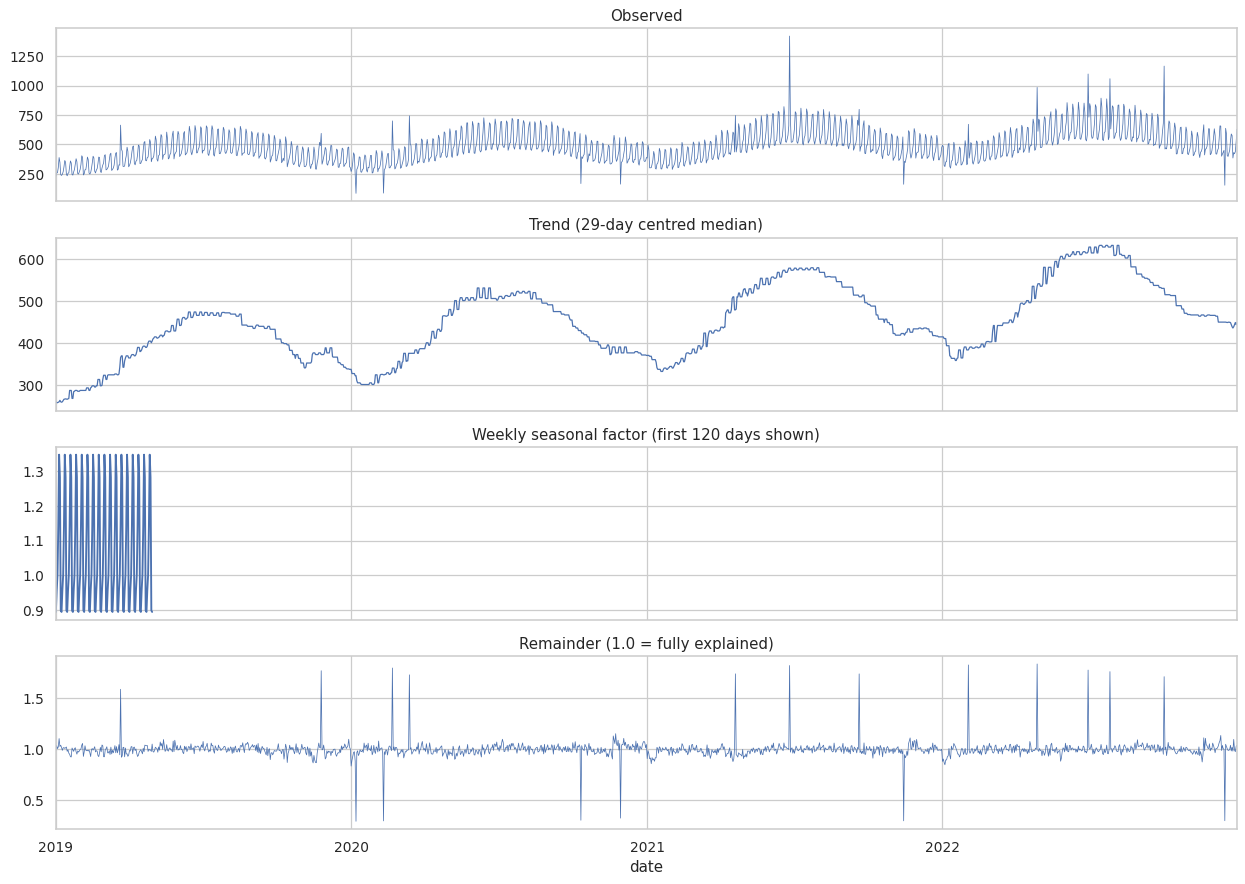

In [11]:
trend7 = daily.rolling(29, center=True, min_periods=15).median()   # robust trend (variable name kept short)
weekly_ratio = (daily / trend7).dropna()
weekly_pattern = weekly_ratio.groupby(weekly_ratio.index.dayofweek).mean()
seasonal_w = pd.Series(weekly_pattern.reindex(daily.index.dayofweek).values, index=daily.index)
remainder = (daily / (trend7 * seasonal_w)).dropna()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
daily.plot(ax=axes[0], lw=0.6); axes[0].set_title("Observed")
trend7.plot(ax=axes[1], lw=1); axes[1].set_title("Trend (29-day centred median)")
seasonal_w.iloc[:120].plot(ax=axes[2]); axes[2].set_title("Weekly seasonal factor (first 120 days shown)")
remainder.plot(ax=axes[3], lw=0.6); axes[3].set_title("Remainder (1.0 = fully explained)")
plt.tight_layout()
plt.show()

Unusual days found: 19


,sales,expected,vs_expected_%,weekday
date,,,,
2020-01-07,85,289.0,-71.0,Tuesday
2020-02-10,87,292.0,-70.0,Monday
2020-10-11,168,552.0,-70.0,Sunday
2021-11-14,162,543.0,-70.0,Sunday
2022-12-16,154,514.0,-70.0,Friday
2020-11-29,163,502.0,-68.0,Sunday
2020-01-01,270,323.0,-16.0,Wednesday
2019-03-22,664,418.0,59.0,Friday
2022-10-02,1165,680.0,71.0,Sunday


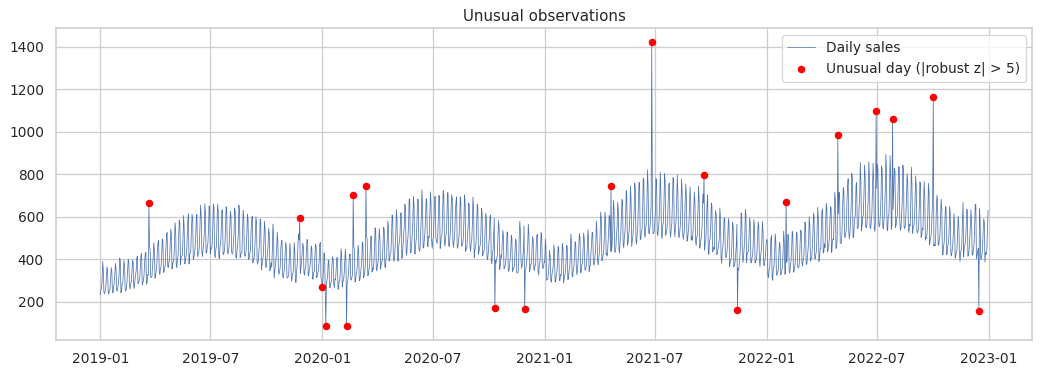

In [12]:
lr = np.log(remainder)
mad = np.median(np.abs(lr - lr.median()))
robust_z = 0.6745 * (lr - lr.median()) / mad
unusual = robust_z[np.abs(robust_z) > 5].index

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily, lw=0.6, label="Daily sales")
ax.scatter(unusual, daily.loc[unusual], color="red", s=25, zorder=3, label="Unusual day (|robust z| > 5)")
ax.set_title("Unusual observations")
ax.legend()
plt.show()

out = pd.DataFrame({"sales": daily.loc[unusual], "expected": (trend7 * seasonal_w).loc[unusual].round(0)})
out["vs_expected_%"] = ((out["sales"] / out["expected"] - 1) * 100).round(0)
print("Unusual days found:", len(out))
out.sort_values("vs_expected_%").assign(weekday=lambda x: x.index.day_name())

These days are **kept** in the data: promotions and outages are real business events the model will see again. In a production setting they would be encoded with a promotion/holiday flag when such information is available.

## 4. Feature engineering
Three groups of features, all computed so that a day only uses **past** information:

| Group | Features |
|---|---|
| Calendar | day of week, month, day of year (sin/cos encoded), weekend flag, festive-season flag (20 Nov – 31 Dec), time index |
| Lag | sales 1, 7, 14 and 28 days earlier |
| Rolling window | mean of the previous 7 and 28 days, standard deviation of the previous 7 days |

Rolling features use `shift(1)` first, so the current day's value never leaks into its own features.

In [13]:
T0 = daily.index.min()

def calendar_features(idx):
    idx = pd.DatetimeIndex(idx)
    f = pd.DataFrame(index=idx)
    f["dow"] = idx.dayofweek
    f["month"] = idx.month
    f["doy_sin"] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * idx.dayofyear / 365.25)
    f["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    f["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    f["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    f["is_festive"] = (((idx.month == 11) & (idx.day >= 20)) | (idx.month == 12)).astype(int)
    f["t"] = (idx - T0).days
    return f

def make_features(s):
    f = pd.DataFrame(index=s.index)
    for k in (1, 7, 14, 28):
        f["lag_%d" % k] = s.shift(k)
    f["roll_7"] = s.shift(1).rolling(7).mean()
    f["roll_28"] = s.shift(1).rolling(28).mean()
    f["roll_std_7"] = s.shift(1).rolling(7).std()
    return f.join(calendar_features(s.index))

feat = make_features(daily)
FEATURES = list(feat.columns)
data = feat.assign(y=daily).dropna()          # first 28 days have no 28-day lag
print("Feature matrix:", data.shape)
data.head()

Feature matrix: (1433, 17)


,lag_1,lag_7,lag_14,lag_28,roll_7,roll_28,roll_std_7,dow,month,doy_sin,doy_cos,dow_sin,dow_cos,is_weekend,is_festive,t,y
date,,,,,,,,,,,,,,,,,
2019-01-29,253.0,240.0,234.0,231.0,301.857143,292.035714,53.414819,1,1,0.478434,0.878124,0.781831,0.623490,0,0,28,249
2019-01-30,249.0,267.0,255.0,257.0,303.142857,292.678571,51.760437,2,1,0.493468,0.869764,0.974928,-0.222521,0,0,29,269
2019-01-31,269.0,288.0,259.0,261.0,303.428571,293.107143,51.532699,3,1,0.508356,0.861147,0.433884,-0.900969,0,0,30,288
2019-02-01,288.0,334.0,313.0,304.0,303.428571,294.071429,51.532699,4,2,0.523094,0.852275,-0.433884,-0.900969,0,0,31,330
2019-02-02,330.0,379.0,360.0,389.0,302.857143,295.000000,51.158019,5,2,0.537677,0.843151,-0.974928,-0.222521,1,0,32,404


## 5. Chronological train / test split
Time series must **never** be shuffled. The last 90 days are held out as the test set; everything before is training data.

In [14]:
HORIZON = 90
split_date = daily.index[-HORIZON]
train = data[data.index < split_date]
test_dates = daily.index[daily.index >= split_date]

print("Train:", train.index.min().date(), "->", train.index.max().date(), "(%d rows)" % len(train))
print("Test :", test_dates.min().date(), "->", test_dates.max().date(), "(%d days)" % len(test_dates))
y_test = daily.loc[test_dates]
history = daily[daily.index < split_date]

Train: 2019-01-29 -> 2022-10-02 (1343 rows)
Test : 2022-10-03 -> 2022-12-31 (90 days)


## 6. Models
**Baselines** (no learning — the bar every model must beat)
- *Naive*: tomorrow = today
- *Seasonal naive*: same weekday last week
- *28-day moving average*: flat forecast

**Machine-learning models** (use the Section 4 features)
- Ridge regression · Random Forest · Histogram Gradient Boosting

**Multi-step forecasting.** To forecast 90 days ahead we cannot know the true lag values of future days, so the ML models forecast **recursively**: predict day 1, feed that prediction into the lag/rolling features for day 2, and so on. This is the honest way to measure accuracy — scoring with true lags would be unrealistically optimistic.

In [15]:
def recursive_forecast(model, hist, dates):
    values = list(hist.values)
    preds = []
    for dt in dates:
        row = {"lag_1": values[-1], "lag_7": values[-7], "lag_14": values[-14], "lag_28": values[-28],
               "roll_7": np.mean(values[-7:]), "roll_28": np.mean(values[-28:]),
               "roll_std_7": np.std(values[-7:], ddof=1)}
        row.update(calendar_features([dt]).iloc[0].to_dict())
        p = float(model.predict(pd.DataFrame([row])[FEATURES])[0])
        values.append(p)
        preds.append(p)
    return pd.Series(preds, index=dates)

def naive_forecast(hist, dates):
    return pd.Series(hist.iloc[-1], index=dates)

def seasonal_naive_forecast(hist, dates):
    last_week = hist.iloc[-7:].values
    return pd.Series([last_week[i % 7] for i in range(len(dates))], index=dates)

def moving_average_forecast(hist, dates, window=28):
    return pd.Series(hist.iloc[-window:].mean(), index=dates)

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAPE %": mape(y_true.values, y_pred.values)}

### 6.1 Time-aware hyper-parameter tuning
Tuning uses `TimeSeriesSplit` (each fold trains on the past and validates on the following block) — never a random K-fold. Only the training period is used.

In [16]:
X_tr, y_tr = train[FEATURES], train["y"]
tscv = TimeSeriesSplit(n_splits=4)

gs_hgb = GridSearchCV(
    HistGradientBoostingRegressor(random_state=RS),
    {"learning_rate": [0.03, 0.06, 0.1], "max_depth": [3, 5, None], "min_samples_leaf": [10, 30]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1).fit(X_tr, y_tr)
print("HistGradientBoosting best:", gs_hgb.best_params_, "| CV MAE = %.1f" % -gs_hgb.best_score_)

gs_rf = GridSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=RS, n_jobs=-1),
    {"max_depth": [8, 14, None], "min_samples_leaf": [2, 5, 10]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1).fit(X_tr, y_tr)
print("Random Forest best       :", gs_rf.best_params_, "| CV MAE = %.1f" % -gs_rf.best_score_)

gs_ridge = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("m", Ridge())]),
    {"m__alpha": [0.1, 1, 10, 100]},
    cv=tscv, scoring="neg_mean_absolute_error").fit(X_tr, y_tr)
print("Ridge best               :", gs_ridge.best_params_, "| CV MAE = %.1f" % -gs_ridge.best_score_)

HistGradientBoosting best: {'learning_rate': 0.06, 'max_depth': 3, 'min_samples_leaf': 30} | CV MAE = 26.4
Random Forest best       : {'max_depth': 14, 'min_samples_leaf': 5} | CV MAE = 27.8
Ridge best               : {'m__alpha': 10} | CV MAE = 23.8


## 7. Forecast the 90-day test period and evaluate

In [17]:
ml_models = {"Ridge": gs_ridge.best_estimator_, "Random Forest": gs_rf.best_estimator_,
             "Hist Gradient Boosting": gs_hgb.best_estimator_}

preds = {
    "Naive": naive_forecast(history, test_dates),
    "Seasonal naive (7d)": seasonal_naive_forecast(history, test_dates),
    "Moving average (28d)": moving_average_forecast(history, test_dates),
}
for name, m in ml_models.items():
    preds[name] = recursive_forecast(m, history, test_dates)

results = pd.DataFrame({k: score(y_test, v) for k, v in preds.items()}).T.round(2).sort_values("RMSE")
results

,MAE,RMSE,MAPE %
Ridge,26.65,50.00,7.31
Hist Gradient Boosting,51.02,73.16,12.22
Random Forest,76.08,106.41,16.81
Moving average (28d),120.68,142.44,28.85
Seasonal naive (7d),127.07,214.19,25.70
Naive,661.72,668.60,142.17


Best model on the 90-day hold-out (lowest RMSE): Ridge


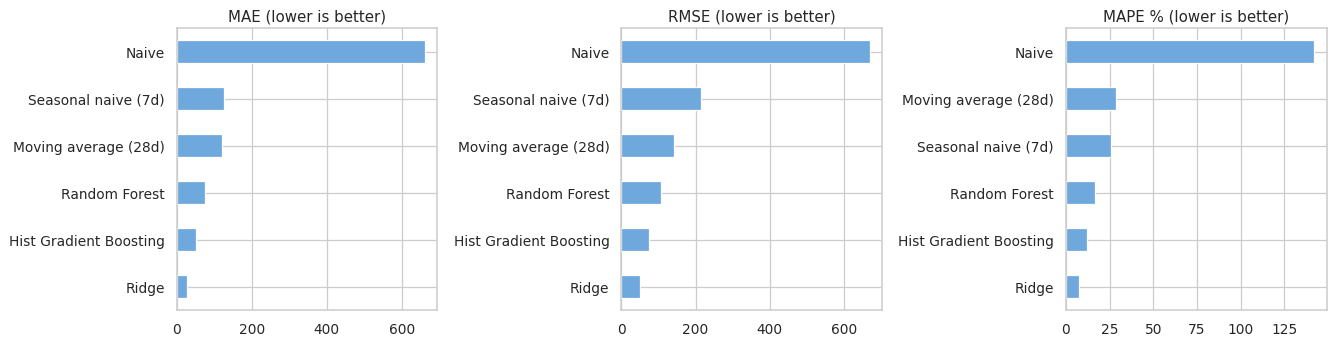

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, metric in zip(ax, ["MAE", "RMSE", "MAPE %"]):
    results[metric].sort_values().plot(kind="barh", ax=a, color="#6fa8dc")
    a.set_title(metric + " (lower is better)")
plt.tight_layout()
plt.show()

best_name = results["RMSE"].idxmin()
print("Best model on the 90-day hold-out (lowest RMSE):", best_name)

### Actual vs predicted

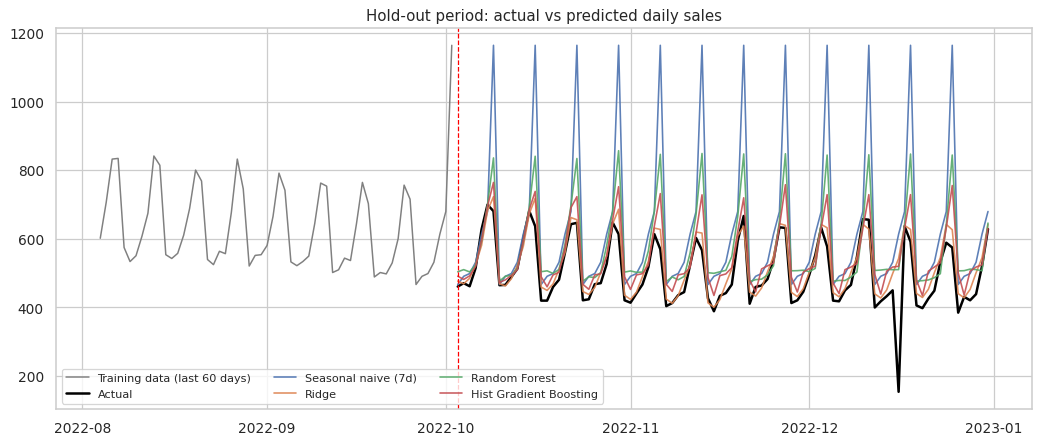

In [19]:
fig, ax = plt.subplots(figsize=(14, 5.5))
ctx = history.iloc[-60:]
ax.plot(ctx.index, ctx.values, color="grey", lw=1.2, label="Training data (last 60 days)")
ax.plot(y_test.index, y_test.values, color="black", lw=2, label="Actual")
for name in ["Seasonal naive (7d)", "Ridge", "Random Forest", "Hist Gradient Boosting"]:
    ax.plot(preds[name].index, preds[name].values, lw=1.3, alpha=0.9, label=name)
ax.axvline(split_date, color="red", ls="--", lw=1)
ax.set_title("Hold-out period: actual vs predicted daily sales")
ax.legend(ncol=3, fontsize=9)
plt.show()

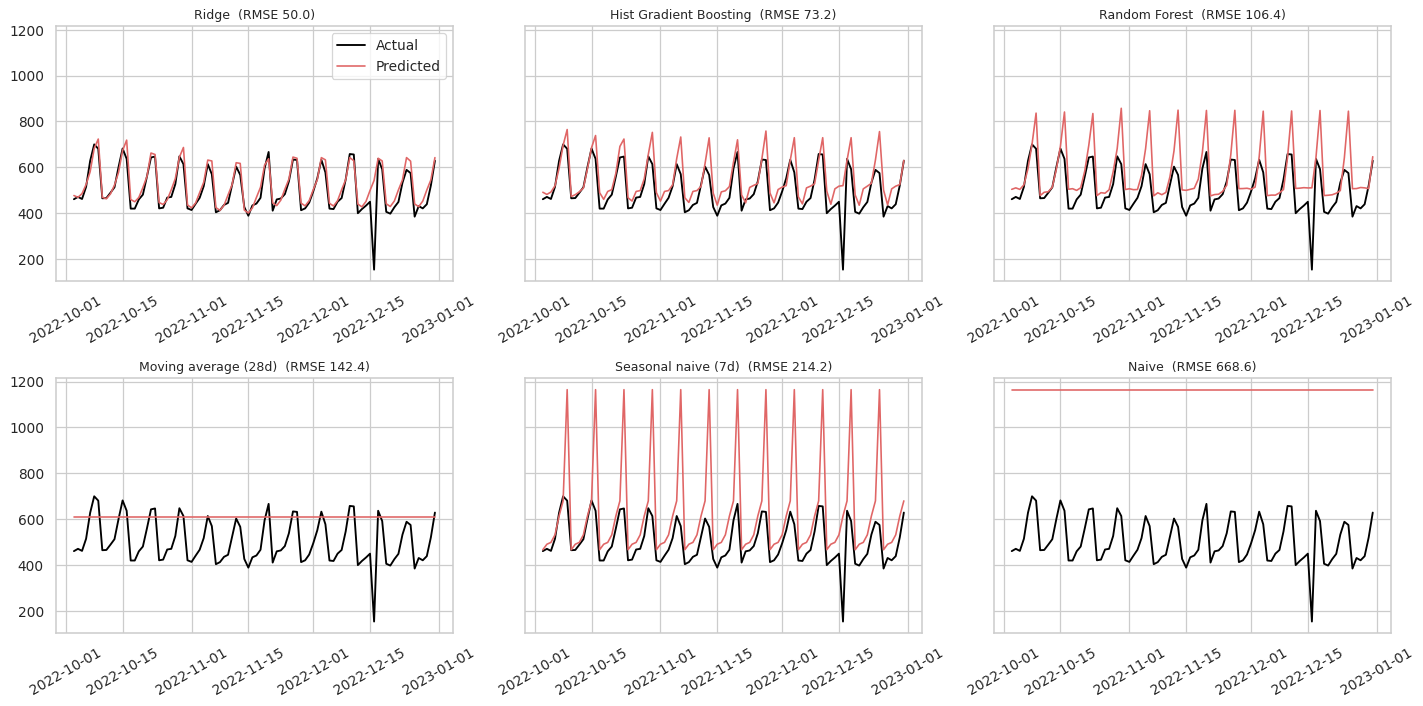

In [20]:
# One panel per model for a clearer view
names = [n for n in results.index]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, name in zip(axes.ravel(), names):
    ax.plot(y_test.index, y_test.values, color="black", lw=1.5, label="Actual")
    ax.plot(preds[name].index, preds[name].values, color="#e06666", lw=1.3, label="Predicted")
    ax.set_title("%s  (RMSE %.1f)" % (name, results.loc[name, "RMSE"]), fontsize=10)
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### 7.1 Residual analysis of the best model

Mean error (bias): -20.8 units/day | residual std: 45.7


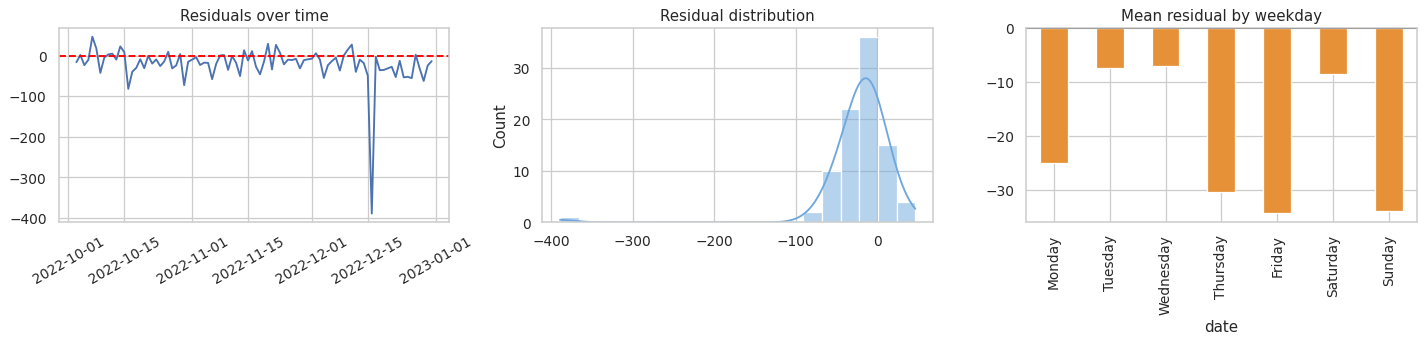

In [21]:
resid = y_test - preds[best_name]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(resid.index, resid.values); ax[0].axhline(0, color="red", ls="--"); ax[0].set_title("Residuals over time"); ax[0].tick_params(axis="x", rotation=30)
sns.histplot(resid, kde=True, ax=ax[1], color="#6fa8dc"); ax[1].set_title("Residual distribution")
resid.groupby(resid.index.day_name()).mean().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).plot(kind="bar", ax=ax[2], color="#e69138")
ax[2].set_title("Mean residual by weekday"); ax[2].axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()
print("Mean error (bias): %.1f units/day | residual std: %.1f" % (resid.mean(), resid.std()))

### 7.2 Recursive vs one-step-ahead accuracy
If true lag values were available every day (forecasting just **one day ahead**), accuracy is much higher. This shows how much accuracy is lost when forecasting a long horizon — an important point when explaining results to stakeholders.

In [22]:
best_ml = [n for n in results.index if n in ml_models][0]
test_feat = data.loc[data.index >= split_date]
one_step = pd.Series(ml_models[best_ml].predict(test_feat[FEATURES]), index=test_feat.index)
cmp = pd.DataFrame({"90-day recursive forecast": score(y_test, preds[best_ml]),
                    "1-day-ahead (true lags)": score(y_test, one_step)}).T.round(2)
print("Best ML model:", best_ml)
cmp

Best ML model: Ridge


,MAE,RMSE,MAPE %
90-day recursive forecast,26.65,50.00,7.31
1-day-ahead (true lags),23.50,47.35,6.56


## 8. Forecast future sales (next 90 days)
The best machine-learning model is **re-trained on all available history** (train + test) and used to forecast the 90 days beyond the end of the data. The shaded band is an approximate ±1 RMSE range from the back-test; real uncertainty grows with the horizon.

,date,forecast_sales
0,2023-01-01,561
1,2023-01-02,379
2,2023-01-03,376
3,2023-01-04,397
4,2023-01-05,435
5,2023-01-06,490
6,2023-01-07,587
7,2023-01-08,565
8,2023-01-09,373
9,2023-01-10,373


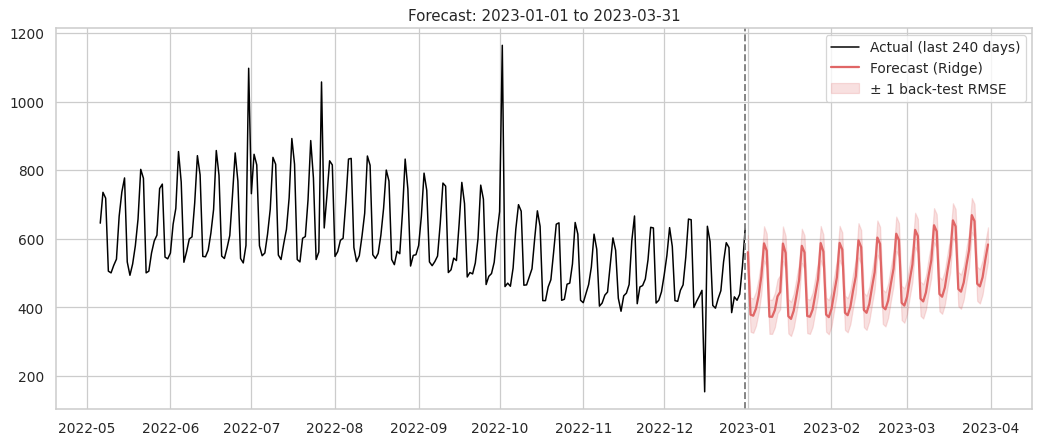

In [23]:
final_name = best_ml
from sklearn.base import clone
final_model = clone(ml_models[final_name]).fit(data[FEATURES], data["y"])

future_dates = pd.date_range(daily.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
future = recursive_forecast(final_model, daily, future_dates)
band = results.loc[final_name, "RMSE"]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(daily.iloc[-240:], color="black", lw=1.2, label="Actual (last 240 days)")
ax.plot(future, color="#e06666", lw=1.8, label="Forecast (%s)" % final_name)
ax.fill_between(future.index, future - band, future + band, color="#e06666", alpha=0.2, label="± 1 back-test RMSE")
ax.axvline(daily.index[-1], color="grey", ls="--")
ax.set_title("Forecast: %s to %s" % (future.index[0].date(), future.index[-1].date()))
ax.legend()
plt.show()

forecast_df = pd.DataFrame({"date": future.index, "forecast_sales": future.round(0).astype(int).values})
import os
os.makedirs("../outputs", exist_ok=True)
forecast_df.to_csv("../outputs/sales_forecast_next_90_days.csv", index=False)
forecast_df.head(10)

## 9. Observations about future sales and seasonal behaviour

In [24]:
same_period_last_year = daily[(daily.index >= future.index[0] - pd.DateOffset(years=1)) &
                              (daily.index <= future.index[-1] - pd.DateOffset(years=1))]
print("Forecast window         : %s to %s" % (future.index[0].date(), future.index[-1].date()))
print("Forecast total sales    : {:,.0f}".format(future.sum()))
print("Same window last year   : {:,.0f}".format(same_period_last_year.sum()))
print("Implied YoY growth      : %.1f%%" % ((future.sum() / same_period_last_year.sum() - 1) * 100))
print("Forecast daily average  : %.0f (last 90 actual days: %.0f)" % (future.mean(), daily.iloc[-90:].mean()))
print()
print("Strongest weekday  : %s (index %.2f)   | weakest: %s (index %.2f)" % (dow_idx.idxmax(), dow_idx.max(), dow_idx.idxmin(), dow_idx.min()))
print("Peak month         : %s (index %.2f)   | trough: %s (index %.2f)" % (month_idx.idxmax(), month_idx.max(), month_idx.idxmin(), month_idx.min()))

fw = future.groupby(future.index.day_name()).mean().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print("\nForecast average by weekday:")
print(fw.round(0).to_string())

Forecast window         : 2023-01-01 to 2023-03-31
Forecast total sales    : 43,690
Same window last year   : 38,931
Implied YoY growth      : 12.2%
Forecast daily average  : 485 (last 90 actual days: 503)

Strongest weekday  : Sat (index 1.29)   | weakest: Tue (index 0.84)
Peak month         : Jul (index 1.23)   | trough: Jan (index 0.74)

Forecast average by weekday:
Monday       405.0
Tuesday      398.0
Wednesday    423.0
Thursday     469.0
Friday       512.0
Saturday     611.0
Sunday       589.0


### Key observations
- **Trend:** sales grow steadily year over year, so the 365-day average keeps rising; the forecast continues that upward level rather than reverting to older, lower levels.
- **Weekly pattern:** sales build through the week and peak on **Friday–Sunday**, with Monday/Tuesday the quietest days. Staffing, stock replenishment and promotions should follow this rhythm.
- **Yearly pattern:** a clear annual cycle — sales peak in mid-year (June–July) and fall to a low in January; November–December sit well above the January–February trough, helped by the festive season.
- **Unusual days:** a handful of days are far above (promotions) or below (outages / stock-outs) expectation. Protecting availability on high-demand days and planning promotions explicitly would reduce forecast error further.
- **Accuracy:** on this dataset the regularised linear model (Ridge) is the most accurate on the 90-day hold-out and every learned model beats the simple baselines. Tree ensembles cannot extrapolate a rising trend beyond the range seen in training, and recursive forecasting compounds their small errors, which explains their weaker showing. Accuracy is highest for the near term and degrades with horizon (Section 7.2), so forecasts should be refreshed regularly.
- **Baseline note:** the *Naive* forecast is especially poor because it simply repeats the last training day, which happens to be an unusually high day.
- **Business use:** use the forecast for inventory and workforce planning; re-train monthly and track MAE/MAPE against actuals to detect drift.

### Limitations & next steps
- No external drivers (price, promotions calendar, holidays, weather, marketing spend) are used. Adding them is the biggest likely accuracy gain.
- Forecasting is done for total sales; store- or item-level models (or hierarchical reconciliation) would support finer decisions.
- Statistical models such as SARIMA/ETS/Prophet can be added as further comparisons (`statsmodels`, `prophet`).